# Motoneuron pool simulation model

This notebook implements a comprehensive simulation of motoneuron pools with excitatory, inhibitory inputs and heterogeneous neuromodulatory input. The model computes firing rates, analyzes recruitment/derecruitment dynamics, and validates against experimental data.

**Key features:**
- Biophysical motoneuron model with multiple ion channels (Na⁺, K⁺, Ca²⁺)
- Different input profiles (triangular, trapezoidal, sinusoidal, chirp)
- Hysteresis analysis and recruitment threshold computation
- Comparison with experimental data
- Visualization tools for spike rasters, trajectories, and firing rates

---

## 1. Environment setup

### 1.1 Package imports

In [2]:
# Core packages
using Distributions, Random
using Parameters, Match, SymDict

# Data handling
using JLD2, MAT, CSV, DataFrames, Serialization

# Numerical methods
using DSP, NumericalIntegration, Polynomials
using Optim, JuMP, Ipopt

# Visualization
using Plots, CairoMakie, Makie
using Colors, ColorSchemes

# Python interop and logging
using PyCall, PyPlot
using Wandb, Logging

println("✓ All packages loaded successfully")

✓ All packages loaded successfully


### 1.2 Load custom functions

In [13]:
# Define path to custom functions (ADJUST THIS PATH FOR YOUR SYSTEM)
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_run_simulations"

# Load all .jl files from the directory
if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
else
    error("Functions directory not found. Please update folder_path variable.")
end

✓ Loaded: calculate_rates_with_timebase.jl
✓ Loaded: conv_spikes_rates.jl
✓ Loaded: creation_model.jl
✓ Loaded: creation_model_controller.jl
✓ Loaded: filter_input.jl
✓ Loaded: plot_MN_trajectory.jl
✓ Loaded: plot_spike_raster.jl
✓ Loaded: run_sim.jl
✓ Loaded: run_sim_noise.jl
✓ Loaded: run_sim_onemn.jl
✓ Loaded: sim_ode_online_control_exp.jl


---

## 2. Model parameters to build the model

### 2.1 Load data
The calcium channel activation thresholds (VthCa) have been optimized to match experimental hysteresis data. If you don't have optimized data, the code will use default values.

In [3]:
# Load optimized calcium channel data
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject1_gamma1.jld2" VthCa_newTA

nr_s = size(VthCa_newTA, 2)  # Number of motoneurons to simulate

println("✓ Loaded optimized VthCa data")
println("Number of motoneurons: ", nr_s)

✓ Loaded optimized VthCa data
Number of motoneurons: 181


### 2.2 Morphological parameters

Define the anatomical properties of motoneurons. These parameters vary across the pool to create physiological heterogeneity.

**Parameter ranges:**
- Rheobase: 3.5-6.5 nA (current threshold for spiking)
- Soma radius (rs): 38.75-41.25 μm
- Soma length (ls): 77.5-82.5 μm
- Dendrite radius (rd): 20.75-31.25 μm
- Dendrite length (ld): 5500-6800 μm

In [5]:
# Rheobase with small random noise for biological variability
rheobase_S = LinRange(3.5, 6.5, nr_s) .+ rand(Normal(0.0, 0.05), nr_s)  # nA

# Soma dimensions (converted to cm)
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000  # cm
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000    # cm
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000    # Ω⋅cm

# Dendrite dimensions (converted to cm)
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000   # cm
ld_S = LinRange(5500.0, 6800.0, nr_s) ./ 10000 # cm
rmd_S = LinRange(14.4, 10.70, nr_s) .* 1000    # Ω⋅cm

println("✓ Morphological parameters defined")

✓ Morphological parameters defined


### 2.3 Ion channel conductances

Maximum conductances for each ion channel type (mS/cm²). These determine the strength of ionic currents during action potential generation.

**Channel types:**
- **gNa:** Fast sodium channels (action potential upstroke)
- **gKf:** Fast potassium channels (rapid repolarization)
- **gKs:** Slow potassium channels (adaptation)
- **gCa:** Calcium channels (persistent inward current, PIC)

In [7]:
# Maximum conductances (mS/cm²)
max_gna = 30.0                          # Sodium
max_gkf_S = ones(nr_s) .* 4.0          # Fast potassium
max_gks_S = LinRange(16, 25, nr_s)     # Slow potassium
max_gca_S = LinRange(0.038, 0.029, nr_s)  # Calcium

println("✓ Ion channel conductances defined")

✓ Ion channel conductances defined


### 2.4 Gating variable kinetics

Rate constants (ms⁻¹) for ion channel gating dynamics. These control how quickly channels open/close.

**Gating variables:**
- **m, h:** Sodium channel activation/inactivation
- **n:** Fast potassium channel activation
- **q:** Slow potassium channel activation
- **p:** Calcium channel activation (dendritic)

In [8]:
# Sodium channel kinetics (ms⁻¹)
αm = ones(nr_s) .* 22.0
βm = ones(nr_s) .* 13.0
αh_S = ones(nr_s) .* 0.5
βh_S = ones(nr_s) .* 4.0

# Potassium channel kinetics (ms⁻¹)
αn_S = ones(nr_s) .* 1.5
βn_S = ones(nr_s) .* 0.1
αq_S = ones(nr_s) .* 1.5
βq_S = LinRange(0.025, 0.038, nr_s)

# Calcium channel kinetics (ms⁻¹)
αp_D = 0.008
βp_D = LinRange(0.014, 0.016, nr_s)

# Calcium channel voltage threshold
Vthca_S = VthCa_newTA[1, :]

println("✓ Gating kinetics defined")

✓ Gating kinetics defined


### 2.5 Force-related parameters

Parameters for computing muscle force from motoneuron firing patterns.

**Twitch properties:**
- **Apeak:** Peak twitch force
- **tpeak:** Time to peak force
- **tetanic:** Tetanic force scaling factor

In [9]:
# Force parameters
Apeak_S = LinRange(0.103, 0.123, nr_s)
tpeak_S = LinRange(110.0, 100.0, nr_s)
tetanic_S = LinRange(0.393, 0.491, nr_s)

println("✓ Force parameters defined")

✓ Force parameters defined


### 2.6 Neuromodulation parameters

Neuromodulatory amplification factors that affect calcium channel properties.

**Key concept:** Neuromodulation can amplify persistent inward currents (PICs), affecting recruitment hysteresis.

In [10]:
# Neuromodulatory amplification
γa = 1.0
γh = ones(nr_s)

# Inhibitory factor (inversely proportional to VthCa)
IF = zeros(nr_s)
max_val = maximum(VthCa_newTA[1, :])
min_val = minimum(VthCa_newTA[1, :])

for i in 1:length(VthCa_newTA[1, :])
    IF[i] = 1.0 - (VthCa_newTA[1, i] - min_val) / (max_val - min_val)
end

# Alternative: uniform inhibition (uncomment if needed)
# IF = LinRange(1.0, 1.0, nr_s)

println("✓ Neuromodulation parameters defined")

✓ Neuromodulation parameters defined


### 2.7 Reversal potentials and synaptic parameters

**Important note:** These reversal potentials are centered at 0 mV for computational convenience. To convert to real physiological values, subtract 65 mV (resting potential).

In [11]:
# Reversal potentials (mV, centered at 0)
EL = 0; ENa = 120; ECa = 140; EK = -10; Ee = 70; Ei = -16

# Synaptic conductances
Ge = 0.6; Gi = 0.5

# Initial voltages
Vd0 = 0.0; Vs0 = 0.0

# Refractory period and pulse duration
rp = 5.0
pd = 1.0

println("✓ Electrical parameters defined")

✓ Electrical parameters defined


---

## 3. Input signal generation

### 3.1 Excitatory input profile

Create the excitatory drive signal. Default is a triangular ramp, but multiple profiles are available.

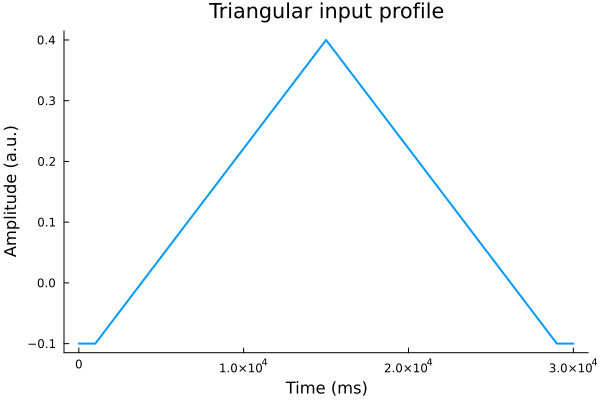

In [12]:
# Triangular input profile
amplitude = 0.4
tr_length = 28000
sim_length = 30000

half_triang = div(tr_length, 2)
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length=half_triang + 1)
down = range(amplitude, -0.1, length=tr_length - half_triang + 1)
input = vcat(flat_line, up[2:end], down[2:end], flat_line)

Plots.plot(input, xlabel="Time (ms)", ylabel="Amplitude (a.u.)",title="Triangular input profile", legend=false, linewidth=2, grid=false)


### 3.2 Alternative excitatory profiles (optional)

Uncomment one of the following code blocks to use alternative input patterns.

In [ ]:
# === TRAPEZOIDAL ===
# flat_length = 20000
# remaining_length = sim_length - flat_length
# edge_length = div(remaining_length, 2)
# flat = fill(amplitude, flat_length)
# up = range(0, amplitude, length=edge_length + 1)
# down = range(amplitude, 0, length=edge_length + 1)
# input = vcat(up[2:end], flat, down[2:end])

In [ ]:
# === SINUSOIDAL ===
# sim_length = 5000
# frequency = 0.25  # Hz
# amplitude_min = 0.16
# amplitude_max = 0.4
# duration = 5.0
# t = range(0, stop=duration, length=sim_length)
# phase = 2π .* frequency .* t .- π/2
# signal = sin.(phase)
# signal = (signal .+ 1) ./ 2
# input = signal .* (amplitude_max - amplitude_min) .+ amplitude_min

In [ ]:
# === CHIRP ===
# sim_length = 10000
# duration = 10.0
# f0 = 0.0; f1 = 3.0
# amplitude_min = 0.25; amplitude_max = 1.0
# t = range(0, stop=duration, length=sim_length)
# phase = 2π .* (f0 .* t .+ 0.5 .* (f1 - f0) .* (t.^2 ./ duration))
# signal = sin.(phase .- π/2)
# signal = (signal .+ 1) ./ 2
# input = signal .* (amplitude_max - amplitude_min) .+ amplitude_min

### 3.3 Compute motoneuron properties

Calculate derived electrical properties from morphological parameters.

**Computed properties:**
- **gls, gld:** Leak conductances (soma and dendrite)
- **gc:** Coupling conductance between compartments
- **rn:** Input resistance
- **Vth:** Voltage threshold for spiking
- **cs, cd:** Membrane capacitances
- **Ionic conductances:** Converted from density to absolute values

In [ ]:
# Constants
ri = 70.0  # Intracellular resistivity
cm = 1.0   # Membrane capacitance

# Preallocate arrays
MN_list = []
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s)
gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s)
gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s)
cs_S = zeros(nr_s); cd_S = zeros(nr_s)

# Compute for each motoneuron
for i in 1:nr_s
    # Leak conductances (μS)
    gls_S[i] = ((2π * rs_S[i] * ls_S[i]) / rms_S[i]) * 1e6
    gld_S[i] = ((2π * rd_S[i] * ld_S[i]) / rmd_S[i]) * 1e6
    
    # Coupling conductance (μS)
    gc_S[i] = (2 / ((ri * ld_S[i] / (π * rd_S[i]^2)) + 
                    (ri * ls_S[i] / (π * rs_S[i]^2)))) * 1e6
    
    # Input resistance (MΩ)
    rn_S[i] = 1 / (gls_S[i] + ((gld_S[i] * gc_S[i]) / (gld_S[i] + gc_S[i])))
    
    # Voltage threshold (mV)
    Vth_S[i] = round(rn_S[i] * rheobase_S[i], digits=2)
    
    # Capacitances (nF)
    cs_S[i] = 2π * ls_S[i] * rs_S[i] * cm * 1e3
    cd_S[i] = 2π * ld_S[i] * rd_S[i] * cm * 1e3
    
    # Ionic conductances (μS)
    gna_S[i] = 2π * ls_S[i] * rs_S[i] * max_gna * 1e3
    gkf_S[i] = 2π * ls_S[i] * rs_S[i] * max_gkf_S[i] * 1e3
    gks_S[i] = 2π * ls_S[i] * rs_S[i] * max_gks_S[i] * 1e3
    gca_S[i] = 2π * ld_S[i] * rd_S[i] * max_gca_S[i] * 1e3
    
    # Create parameter dictionary
    S_MN = Dict(
        :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],:gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
        :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],:gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],:βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
        :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],:VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i], :IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],"type" => "All Type")
    
    push!(MN_list, S_MN)
end

MNs = MN_list

println("✓ Computed properties for ", nr_s, " motoneurons")


✓ Computed properties for 181 motoneurons


### 3.4 Inhibitory input profile

Define the inhibitory drive. Multiple profiles are available.

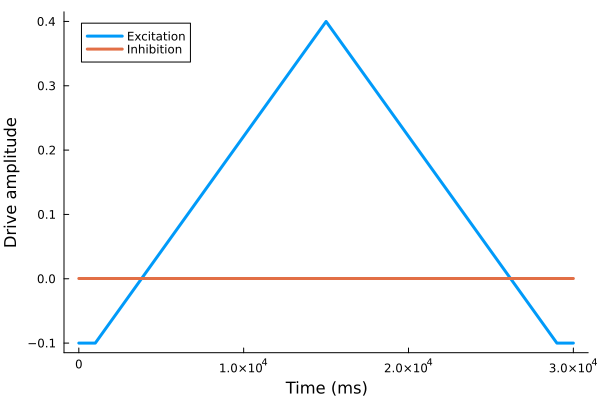

In [ ]:
# Constant inhibition 
inh_factor = 0.001
inh_input = fill(inh_factor * amplitude, sim_length)

# Visualize
Plots.plot(input, label="Excitation", linewidth=3, legend=:topleft, xlabel="Time (ms)", ylabel="Drive amplitude", grid=false)
Plots.plot!(inh_input, label="Inhibition", linewidth=3)


#### Alternative inhibitory profiles (uncomment to use)

In [ ]:
# === INVERSELY PROPORTIONAL ===
# exc_min = minimum(input); exc_max = maximum(input)
# exc_normalized = (input .- exc_min) ./ (exc_max - exc_min)
# inh_factor = 0.9
# inh_input = exc_max .* (1.0 .- inh_factor .* exc_normalized)

In [ ]:
# === PROPORTIONAL ===
# inh_factor = 0.9
# inh_amplitude = 0.4 * inh_factor
# half_triang = div(28000, 2)
# flat_line = fill(0, 1000)
# up = range(0, inh_amplitude, length=half_triang + 1)
# down = range(inh_amplitude, 0, length=28000 - half_triang + 1)
# inh_input = vcat(flat_line, up[2:end], down[2:end], flat_line)

---

## 4. Simulation initialization

### 4.1 Initialize state variables

Set up arrays to store simulation results and initial conditions for all motoneurons.

In [17]:
# Define helper function
_int(num) = floor(Int, num)

# Simulation parameters
const dt = 0.05
tspan = 0:dt:sim_length
sim_time = _int(sim_length / dt)

# Initial conditions
m = 0.0; h = 1.0; n = 0.0; q = 0.0; p = 0.0
m0 = 0.0; h0 = 1.0; n0 = 0.0; q0 = 0.0; p0 = 0.0
t0 = -1.0; t1 = -1.0; SPIKE0 = 0; SPIKE1 = 0

pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

# Storage arrays
spike_arr = zeros(nr_s, sim_time)
vs_arr = zeros(nr_s, sim_time)
pt_arr = zeros(nr_s, sim_time)
mt_arr = zeros(nr_s, sim_time)
ht_arr = zeros(nr_s, sim_time)
nt_arr = zeros(nr_s, sim_time)
qt_arr = zeros(nr_s, sim_time)

# Input arrays
full_input = zeros(nr_s, sim_length)
independantnoise = zeros(nr_s, sim_length)
commoninput = input

println("✓ Simulation initialized")
println("  Time steps: ", sim_time)
println("  Duration: ", sim_length, " ms")

✓ Simulation initialized
  Time steps: 600000
  Duration: 30000 ms


---

## 5. Run simulation of the motoneuron pool

### 5.1 Execute main simulation

This calls the custom `run_sim()` function which implements the numerical integration of the motoneuron pool dynamics.

**Note:** This may take several minutes depending on pool size.

In [ ]:
println("\n" * "="^60)
println("Starting simulation...")
println("This may take several minutes for ", nr_s, " motoneurons.")
println("="^60 * "\n")

@time spike_array, vs_array, pt_arr = run_sim()

println("\n" * "="^60)
println("✓ Simulation completed")
println("="^60)
println("\nResults:")
println("  Total spikes: ", Int(sum(spike_array)))
println("  Active neurons: ", sum(sum(spike_array, dims=2) .> 0), " / ", nr_s)

In [ ]:
#################################
######## LOAD SIMULATION ########
#################################

JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/DR_subject1_TA.jld2" spike_array 

1-element Vector{Symbol}:
 :spike_array

### 5.2 Save simulation results (optional)

Uncomment and modify paths to save your simulation data.

In [ ]:
# Save to JLD2
# JLD2.@save "simulation_results.jld2" spike_array vs_array pt_arr

# Save to MAT (for MATLAB)
# MAT.matwrite("simulation_results.mat", Dict("spike_array" => spike_array,"vs_array" => vs_array))

---

## 6. Visualization

### 6.1 Voltage traces (optional)

Plot somatic voltage traces for all motoneurons. Useful for debugging and understanding model behavior.

In [ ]:
# Uncomment to visualize voltage traces
# WARNING: This can be slow for large numbers of motoneurons

# fig = CairoMakie.Figure(resolution = (2000, 1000))
# rows = ceil(Int, sqrt(nr_s))
# cols = ceil(Int, nr_s / rows)
# for i in 1:nr_s
#     row = div(i - 1, cols) + 1
#     col = mod(i - 1, cols) + 1
#     ax = CairoMakie.Axis(fig[row, col])#) title = "Motoneuron $i", xlabel = "Time", ylabel = "Voltage")
#     CairoMakie.lines!(ax, vs_array[i, 1:600000], label = "Trace $i")
# end
# CairoMakie.display(fig)

### 6.2 Spike raster plot

Visualize spike times for all motoneurons as a raster plot. This is the primary visualization for understanding recruitment patterns.

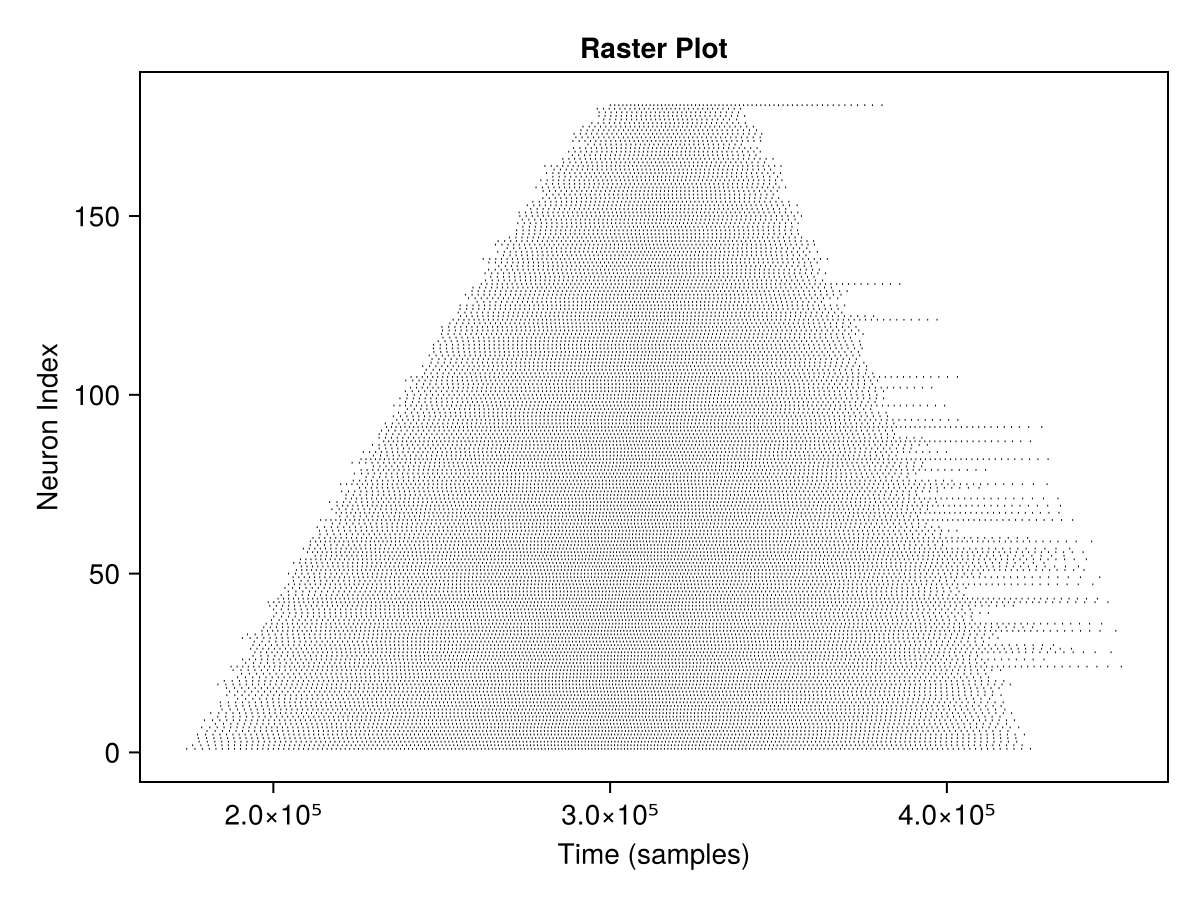

✓ Raster plot generated


In [28]:
# Create raster plot
fig = plot_spike_raster(spike_array)
CairoMakie.display(fig)

println("✓ Raster plot generated")

---

## 7. Firing rate analysis

### 7.1 Compute instantaneous firing rates

Calculate firing rates for each motoneuron using inter-spike intervals.

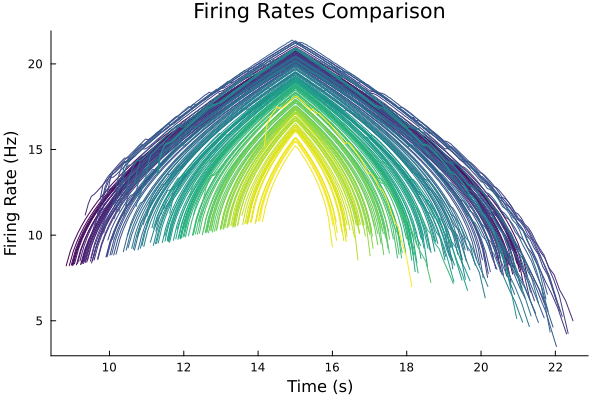

In [33]:
sampling_rate = 20000  # Hz

all_timebases = []
all_rates = []

for mn in 1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

color_map = get(ColorSchemes.viridis, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], color=color_map[i], legend=false, grid=false)
    end
end

display(p)

### 7.2 Normalize firing rate data (optional)

Pad firing rate arrays with NaN to create uniform-length matrices for analysis.

In [ ]:
# Uncomment if needed for analysis

# num_rows = length(all_timebases)
# row_lengths = [length(row) for row in all_timebases]
# max_length = maximum(row_lengths)
# new_all_bases = zeros(nr_s, max_length)

# for i in 1:nr_s
#     rate_per_neuron = all_timebases[i]
#     padding = max_length - length(rate_per_neuron)
#     new_all_bases[i, :] .= vcat(rate_per_neuron, fill(NaN, padding))
# end

### 7.3 Motoneuron trajectory plot

Visualize the relationship between firing rates of pairs of motoneurons in state space.

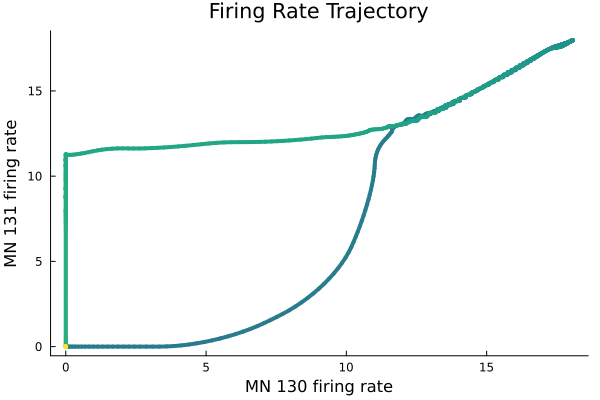

✓ Trajectory generated for neurons 130 and 131


In [30]:
# Plot trajectory for specific pair
mn1 = 130
mn2 = 131

if mn1 <= nr_s && mn2 <= nr_s
    p, avg_traj = plot_MN_trajectory(spike_array, mn1, mn2, v=100)
    display(p)
    println("✓ Trajectory generated for neurons ", mn1, " and ", mn2)
else
    println("⚠️ Selected neurons exceed pool size")
end

---

## 8. Hysteresis analysis

### 8.1 Compute recruitment and derecruitment thresholds

Analyze when each motoneuron recruits (first spike) and derecruits (last spike) to quantify hysteresis.

**Key metrics:**
- **Recruitment threshold:** Excitatory drive level when neuron first fires
- **Derecruitment threshold:** Excitatory drive level when neuron stops firing
- **Hysteresis:** Difference between recruitment and derecruitment (reflects PIC strength)

In [ ]:
#Get excitatory inputs, we need to define them again, because spikes are in samples now 

nr_s=size(spike_array,1)
amplitude=0.4;
sim_length=560000 ;
half_triang = div(sim_length, 2);  
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);

recr_inter_input= zeros(1,nr_s)
derecr_inter_input= zeros(1,nr_s)
hysteresis=zeros(1,nr_s)

for n in 1:nr_s
    if any(spike_array[n, :] .== 1)
        recr_inter_input[1,n]= tr[findfirst(==(1),spike_array[n,:]),:][1] #force at the recruitment threshold relative to the defined exc input
        derecr_inter_input[1,n]=  tr[findlast(==(1),spike_array[n,:]),:][1] #force at the derecruitment threshold
        hysteresis[1,n]= (derecr_inter_input[1,n]/recr_inter_input[1,n]).-1
    else #this is for the case in which for some reason there are no spikes for one of the neurons
        hysteresis[1,n]= NaN
    end
end

hysteresis

### 8.2 Visualize hysteresis distribution

In [35]:
#Get excitatory inputs, we need to define them again, because spikes are in samples now 

nr_s=size(spike_array,1)
amplitude=0.4;
sim_length=560000 ;
half_triang = div(sim_length, 2);  
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);

recr_inter_input= zeros(1,nr_s)
derecr_inter_input= zeros(1,nr_s)
hysteresis=zeros(1,nr_s)

for n in 1:nr_s
    if any(spike_array[n, :] .== 1)
        recr_inter_input[1,n]= tr[findfirst(==(1),spike_array[n,:]),:][1] #force at the recruitment threshold relative to the defined exc input
        derecr_inter_input[1,n]=  tr[findlast(==(1),spike_array[n,:]),:][1] #force at the derecruitment threshold
        hysteresis[1,n]= (derecr_inter_input[1,n]/recr_inter_input[1,n]).-1
    else #this is for the case in which for some reason there are no spikes for one of the neurons
        hysteresis[1,n]= NaN
    end
end

hysteresis

1×181 Matrix{Float64}:
 0.00918822  0.0180901  0.0166649  …  0.00357745  0.00427604  -0.21748

---

## 9. Experimental data comparison

### 9.1 Load experimental data

In [36]:
# Load experimental hysteresis data
exp_data_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_subjects_Avrillonetal/hysteresis1TA.csv"

if isfile(exp_data_path)
    df_h = CSV.read(exp_data_path, DataFrame; header=false)
    hysteresis_exp = df_h[:, 1]
    
    println("✓ Experimental data loaded")
    println("  Number of neurons: ", length(hysteresis_exp))
else
    @warn "Experimental data file not found at: $exp_data_path"
    @warn "Skipping experimental comparison."
    hysteresis_exp = nothing
end

✓ Experimental data loaded
  Number of neurons: 181


### 9.2 Compute model fit (R²)


Model validation:
  R² = 0.722


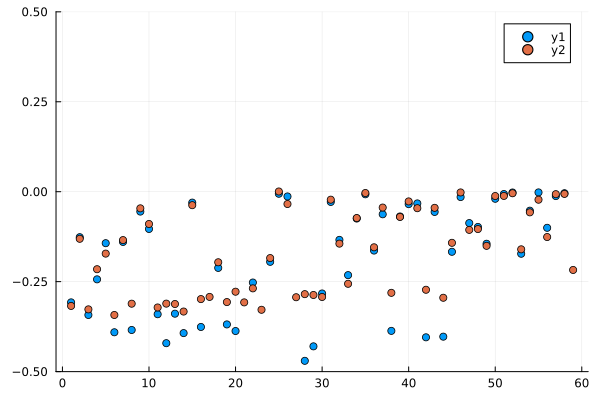

In [41]:
if hysteresis_exp !== nothing
    # Match array sizes
    n_compare = min(length(hysteresis_exp), length(hysteresis[1, :]))
    
    # Filter for neurons with PICs (negative hysteresis only)
    mask = hysteresis_exp[1:n_compare] .< 0
    filtered_exp = hysteresis_exp[1:n_compare][mask]
    filtered_sim = hysteresis[1, 1:n_compare][mask]
    
    # Remove NaN values from simulation
    valid_mask = .!isnan.(filtered_sim)
    filtered_exp = filtered_exp[valid_mask]
    filtered_sim = filtered_sim[valid_mask]
    
    if length(filtered_exp) > 0
        # Calculate R²
        mean_exp = mean(filtered_exp)
        TSS = sum((filtered_exp .- mean_exp).^2)
        RSS = sum((filtered_exp .- filtered_sim).^2)
        R2 = 1 - (RSS / TSS)
        

        println("\nModel validation:")
        println("  R² = ", round(R2, digits=3))
    else
        println("⚠️ No valid neurons for comparison")
    end
else
    println("⚠️ Skipping R² calculation (no experimental data loaded)"
    )
end

Plots.scatter(filtered_exp)
Plots.scatter!(filtered_sim,ylim=(-0.5,0.5))

---

## 10. Additional analyses

### 10.1 Recruitment threshold vs maximum firing rate

Verify the expected inverse relationship (Henneman's size principle).

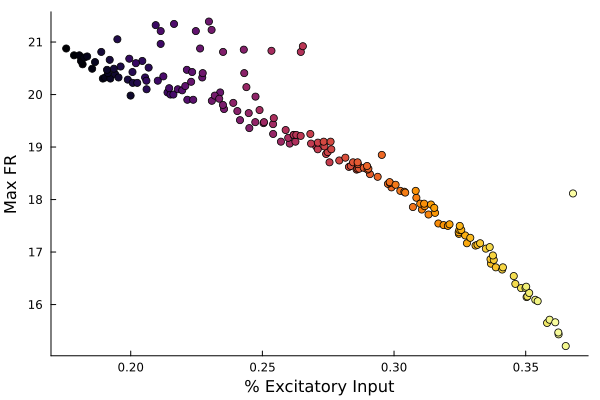

In [44]:
max_vals=zeros(1,nr_s)
color_map = get(ColorSchemes.inferno, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false)

for i in 1:nr_s
    if !isempty(all_rates[i])
        max_vals[1,i]=maximum(all_rates[i])
        Plots.scatter!([recr_inter_input[i]], [max_vals[1,i]],color=color_map[i], grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Max FR")#,ylim=(-0.5, 0.5))
    end
end
display(p)

### 10.2 Motoneuron similarity analysis

Find pairs of motoneurons with similar recruitment thresholds and compare their VthCa values.

In [ ]:
mn_that_is_similar = [Int[] for _ in 1:nr_s]

for i in 1:nr_s

    diff = zeros(Float64, nr_s)

    for j in 1:nr_s
        if i==j #do not compare the MN with itself
            diff[j] = NaN
        else
            diff[j] = abs(recr_inter_input[i] - recr_inter_input[j]) #compare recruitment threshold 
        end
    end

    min_diff = minimum(filter(!isnan, diff)) #find the minimum difference between recruitment thresholds of motoneurons 
    
    mn_that_is_similar[i] = findall(x -> x == min_diff, diff)   # find the most similar mn

end
mn_that_is_similar

motoneuron = Int[]
recr_input = Float64[]
similar_motoneuron = Int[]
similar_recr_input = Float64[]
abs_diff = Float64[]

for i in 1:length(recr_inter_input)

    similar_idx = mn_that_is_similar[i][1]  
    diff_value = abs(Vthca_S[i] - Vthca_S[similar_idx])  #compute the diff of VthCa values
    
    push!(motoneuron, i)
    push!(recr_input, recr_inter_input[i])
    push!(similar_motoneuron, similar_idx)
    push!(similar_recr_input, recr_inter_input[similar_idx])
    push!(abs_diff, diff_value)
end

df = DataFrame(Motoneuron = motoneuron, Recr_Input = recr_input, Similar_Motoneuron = similar_motoneuron, Similar_Recr_Input = similar_recr_input, VthCa_Diff = abs_diff)
println(df)



# findmax(df.VthCa_Diff)
# findmin(df.VthCa_Diff)

181×5 DataFrame
 Row │ Motoneuron  Recr_Input  Similar_Motoneuron  Similar_Recr_Input  VthCa_Diff 
     │ Int64       Float64     Int64               Float64             Float64    
─────┼────────────────────────────────────────────────────────────────────────────
   1 │          1    0.175496                   2            0.178471  0.0
   2 │          2    0.178471                   5            0.18048   0.0
   3 │          3    0.181734                   4            0.181109  0.0
   4 │          4    0.181109                   3            0.181734  0.0
   5 │          5    0.18048                    4            0.181109  0.0
   6 │          6    0.185363                  11            0.186446  0.0
   7 │          7    0.182359                   3            0.181734  0.0
   8 │          8    0.189418                  19            0.188821  0.0
   9 │          9    0.183463                   7            0.182359  0.0
  10 │         10    0.190304                  14           

---

## 11. Parameter optimization (advanced)

### 11.1 Hyperparameter sweep with Weights & Biases

This section demonstrates how to systematically explore parameter space to optimize VthCa values.

**Note:** This requires W&B account setup and can be computationally expensive.

In [ ]:
# Example parameter sweep framework (requires additional setup)

# function simulate_with_params(γh_val, vthca_val, mn_idx)
#     MN_list[mn_idx][:γh] = γh_val
#     MN_list[mn_idx][:VthCa] = vthca_val
#     spike_array, _ = run_sim_optim_constant_inh(mn_idx)
#     # Compute metrics and return
#     return metrics
# end

# # Define parameter ranges
# γh_range = LinRange(0.0, 1.0, 5)
# vthca_range = LinRange(0.0, 5.0, 5)

# # Run sweep
# for γh in γh_range
#     for vthca in vthca_range
#         run_name = "gamma_$(γh)_vthca_$(vthca)"
#         lg = WandbLogger(project="mn_optimization", name=run_name,
#                         config=Dict("gamma_h" => γh, "vthca" => vthca))
#         metrics = simulate_with_params(γh, vthca, 1)
#         # Log results
#     end
# end